# Test technique NLP Classification de commentaires citoyens sur les services publics

**Candidat:** AKOTA yao jerome

**Objectif :** construire un pipeline NLP complet (exploration, prétraitement, vectorisation, modélisation, évaluation, analyse d'erreurs) pour classer 150 commentaires citoyens en trois catégories : Satisfaction, Insatisfaction, Suggestion.

## les importations

In [1]:
import re
import random
import unicodedata
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from wordcloud import WordCloud

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,classification_report, f1_score)
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold,cross_val_predict, cross_val_score,train_test_split)
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

## la Reproductibilité

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

## les Constantes du projet

In [3]:
CHEMIN_DATASET = "dataset_nlp_test_tal.csv"
CATEGORIES = ["Satisfaction", "Insatisfaction", "Suggestion"]
COULEURS = {"Satisfaction": "#2e8b57", "Insatisfaction": "#c0392b", "Suggestion": "#2c6fbb"}
CMAPS_NUAGES = {"Satisfaction": "Greens", "Insatisfaction": "Reds", "Suggestion": "Blues"}

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

## Partie 1 : Exploration & Prétraitement des données
- Chargement et exploitation du dataset

In [4]:
df = pd.read_csv(CHEMIN_DATASET)
print(" Nombre de lignes et colonnes) :", df.shape)
print("\nTypes des colonnes :")
print(df.dtypes)
print("\n Affichier les Valeurs manquantes par colonne :")
print(df.isna().sum())
print("\nIdentifiants uniques :", df["id"].is_unique, 
      "Textes dupliqués :", df["texte"].duplicated().sum())

print("\nAperçu des 10 premières lignes :")
df.head(10)


 Nombre de lignes et colonnes) : (150, 3)

Types des colonnes :
id            int64
texte        object
categorie    object
dtype: object

 Affichier les Valeurs manquantes par colonne :
id           0
texte        0
categorie    0
dtype: int64

Identifiants uniques : True Textes dupliqués : 0

Aperçu des 10 premières lignes :


,id,texte,categorie
0,1,Manque total de communication entre les services.,Insatisfaction
1,2,Il serait bien de proposer des tutoriels vidéo pour les démarches en ligne.,Suggestion
2,3,Envoyer des SMS de confirmation lors de chaque étape du traitement.,Suggestion
3,4,Prévoir des interprètes pour les citoyens ne parlant pas le français.,Suggestion
4,5,Le formulaire en ligne plante au moment de la soumission.,Insatisfaction
5,6,Le personnel semble débordé et les citoyens en pâtissent.,Insatisfaction
6,7,Former les agents sur les droits des usagers pour un meilleur respect.,Suggestion
7,8,J'ai été agréablement surpris par la rapidité du traitement.,Satisfaction
8,9,"Bonne expérience globale, les choses évoluent positivement.",Satisfaction
9,10,Le personnel fait preuve de beaucoup de professionnalisme.,Satisfaction


In [5]:
for categorie in CATEGORIES:
    print(f"{categorie}")
    display(df[df["categorie"] == categorie].sample(4, random_state=SEED)[["id", "texte"]])

Satisfaction


,id,texte
56,57,"Tout s'est bien passé, merci pour votre professionnalisme."
121,122,Le bureau est bien situé et facilement accessible.
107,108,"Processus transparent, j'ai pu suivre l'avancement de mon dossier."
141,142,"J'ai reçu mon document dans les délais, service impeccable."


Insatisfaction


,id,texte
39,40,Les informations données par téléphone étaient erronées.
122,123,On m'a demandé des pièces non mentionnées sur le site officiel.
88,89,Service fermé sans préavis le jour de mon rendez-vous confirmé.
135,136,Le guichet était fermé sans aucune explication ni affichage.


Suggestion


,id,texte
34,35,Mettre en réseau les différentes mairies pour un meilleur partage des données.
110,111,Prévoir une ligne téléphonique distincte pour les urgences administratives.
81,82,Mettre à jour régulièrement le site web avec les nouvelles procédures.
131,132,Afficher clairement les délais de traitement à l'entrée des services.


## Distribution de classe

categorie
Satisfaction      50
Insatisfaction    50
Suggestion        50
Name: count, dtype: int64


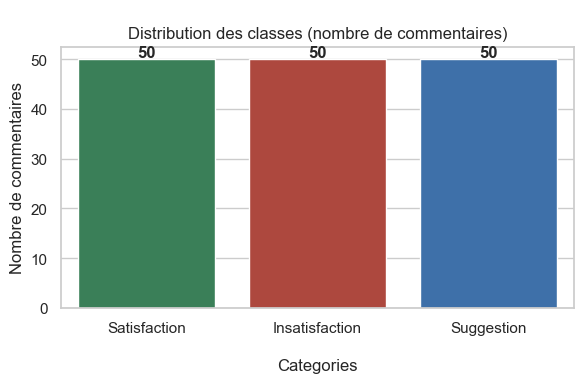

In [6]:
distribution_classes = df["categorie"].value_counts().reindex(CATEGORIES)
print(distribution_classes)

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=distribution_classes.index, y=distribution_classes.values,
            hue=distribution_classes.index, palette=COULEURS, legend=False, ax=ax)
for i, valeur in enumerate(distribution_classes.values):
    ax.text(i, valeur + 0.5, str(valeur), ha="center", fontweight="bold")
ax.set_title("\nDistribution des classes (nombre de commentaires)")
ax.set_xlabel("\nCategories")
ax.set_ylabel("Nombre de commentaires")
plt.tight_layout()
plt.show()

**on voit que Le jeu est bien équilibré (50 / 50 / 50)**

### Calculons la longueur moyenne des textes par catégorie
- `La longueur est mesurée en nombre de mots (séparés par des espaces) et en nombre de caractères`

nb_mots               nb_caracteres              
                  mean   std min max          mean   std min max
categorie                                                       
Satisfaction      8.68  1.63   5  13         57.40  8.33  27  76
Insatisfaction    9.34  1.64   6  13         57.76  7.95  34  78
Suggestion       10.50  1.45   8  15         69.82  5.32  58  84

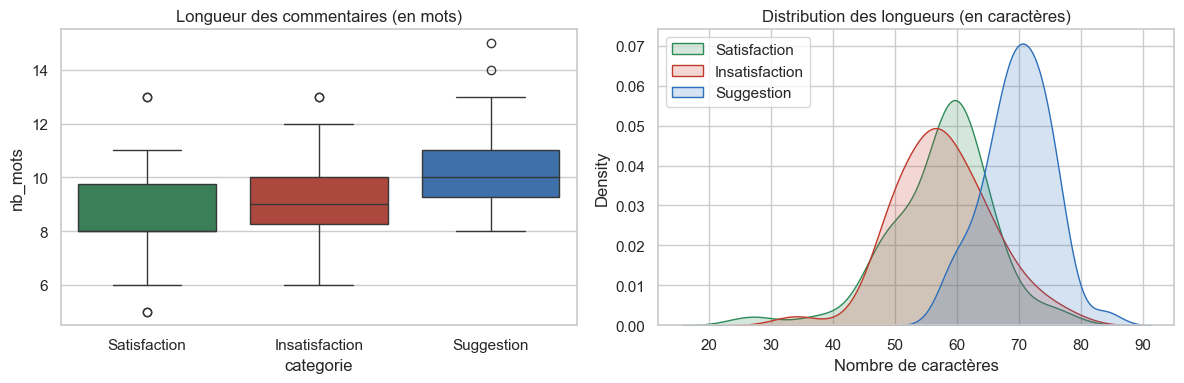

In [7]:
df["nb_mots"] = df["texte"].str.split().str.len()
df["nb_caracteres"] = df["texte"].str.len()

longueurs_par_categorie = (df.groupby("categorie")[["nb_mots", "nb_caracteres"]]
                             .agg(["mean", "std", "min", "max"])
                             .round(2)
                             .loc[CATEGORIES])
display(longueurs_par_categorie)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="categorie", y="nb_mots", order=CATEGORIES,
            hue="categorie", palette=COULEURS, legend=False, ax=axes[0])
axes[0].set_title("Longueur des commentaires (en mots)")
for categorie in CATEGORIES:
    sns.kdeplot(df.loc[df["categorie"] == categorie, "nb_caracteres"],
                label=categorie, color=COULEURS[categorie], fill=True, alpha=0.2, ax=axes[1])
axes[1].set_title("Distribution des longueurs (en caractères)")
axes[1].set_xlabel("Nombre de caractères")
axes[1].legend()
plt.tight_layout()
plt.show()

J'ai mesuré la longueur des commentaires pour voir si elle peut aider à séparer les classes. Les Suggestion sont clairement les plus longues : 10,5 mots en moyenne (≈ 70 caractères), contre 9,3 mots (≈ 58 caractères) pour l'Insatisfaction et 8,7 mots (≈ 57 caractères) pour la Satisfaction. Leur écart-type en caractères est aussi le plus petit (~~ 5) : les suggestions ont presque toutes la même forme, un verbe à l'infinitif ou au conditionnel suivi d'un complément. En revanche, Satisfaction et Insatisfaction ont des longueurs quasi identiques, donc la longueur ne les séparera pas : il faudra s'appuyer sur le vocabulaire. Dernier point important : les commentaires sont courts (5 à 15 mots), donc chaque exemple contient peu d'information. C'est quelque chose à garder en tête pour la suite du pipeline.

# 1-2 Nettoyage du texte
    - Mettre les textes en minuscules
   - Supprimer la ponctuation, les chiffres et les caractères spéciaux
   - Gérer les mots en éwé/mina présents dans certains commentaires
- Supprimer les stopwords français

Tout est regroupé dans une fonction unique pretraiter_texte, appliquée à toute la colonne texte.
Minuscules, accents, ponctuation, chiffres et caractères spéciaux

Voilà les choix que j'ai faits, et pourquoi :

   - Minuscules : je passe tout en .lower(), mais après une normalisation Unicode NFC, pour qu'une lettre accentuée garde toujours la même représentation (sinon le modèle verrait deux mots différents pour un seul é).
   - Accents : je les conserve dans le texte nettoyé. En français ils portent du sens (a/à, ou/où), et ils sont indispensables à l'éwé (wò, yèvu, mègbe). Les variantes d'écriture ( rapidité  /  rapidite ) seront neutralisées plus tard par le vectoriseur avec strip_accents="unicode". Par contre, pour savoir si un mot est un stopword, je compare sans accents.
  -  Ponctuation et caractères spéciaux : tout caractère qui n'est ni une lettre, ni un chiffre, ni un espace est remplacé par un espace. Conséquence : les apostrophes jouent le rôle de séparateurs, donc j'ai devient j ai et l'agent devient l agent. Ça évite de coller l'article au mot qui suit.
   - Chiffres : supprimés, comme demandé . Je sais que c'est une perte d'information (on perd des indices comme <<6 semaines >> ou << 10 minutes >>)

### Gestion des mots éwé / mina
Avant de choisir une méthode, j'ai regardé ce qu'il y a vraiment dans les données : après avoir relevé tout le vocabulaire, seuls 3 commentaires sur 150 sont réellement mixtes français/éwé-mina (les ids 73, 131 et 139). Le commentaire 72 mentionne juste le mot " éwé " dans une phrase française, il ne compte donc pas comme mixte.

J'ai retenu une stratégie " normaliser ", avec trois règles :

    Traduire les termes dont le sens est sûr vers leur équivalent français : akpe -> merci, nyuie -> bien. Comme ça, ces commentaires se rattachent au vocabulaire français de leur classe.
    Supprimer les mots-outils éwé (na, wò), qui jouent le rôle de stopwords.
    Conserver tels quels les autres termes (hafi, mele, mègbe, yèvu) : sans validation par un locuteur natif, je préfère ne pas deviner leur sens.

Je compare les trois stratégies possibles (tout conserver, tout supprimer, normaliser) dans la partie 2, pour voir si ce choix change vraiment quelque chose sur les scores.

In [8]:
def sans_accents(mot):
    return "".join(i for i in unicodedata.normalize("NFD", mot) if unicodedata.category(i) != "Mn")

LEXIQUE_EWE_MINA = {"akpe", "nyuie", "hafi", "mele", "megbe", "yevu", "wo", "na"}
EWE_VERS_FRANCAIS = {"akpe": "merci", "nyuie": "bien"}  
EWE_MOTS_OUTILS = {"na", "wo"}                            


def detecter_ewe_mina(texte):
    jetons = re.sub(r"[^\w\s]|\d|_", " ", texte.lower()).split()
    return [jeton for jeton in jetons if sans_accents(jeton) in LEXIQUE_EWE_MINA]


df["termes_ewe_mina"] = df["texte"].apply(detecter_ewe_mina)
df["a_ewe_mina"] = df["termes_ewe_mina"].str.len() > 0

print("Commentaires contenant des termes éwé/mina :", int(df["a_ewe_mina"].sum()), "/", len(df))
display(df.loc[df["a_ewe_mina"], ["id", "categorie", "texte", "termes_ewe_mina"]])

Commentaires contenant des termes éwé/mina : 3 / 150


,id,categorie,texte,termes_ewe_mina
72,73,Satisfaction,Yèvu service la nyuie hafi!,"[yèvu, nyuie, hafi]"
130,131,Insatisfaction,"Mele via o, service la mègbe trop!","[mele, mègbe]"
138,139,Satisfaction,"Akpe na wò, service très professionnel et efficace.","[akpe, na, wò]"


### Suppression des stopwords français liste et justification
Je n'ai pas utilisé une liste toute faite (NLTK ou spaCy). En la parcourant, j'ai vu qu'elle supprime des mots qui portent justement le sentiment ou le type de commentaire ici. Du coup, j'ai construit ma propre liste avec uniquement des mots grammaticaux (articles, prépositions, pronoms, conjonctions, auxiliaires), et je garde volontairement :

   - les négations : ne, pas, jamais, aucun(e), sans, rien, ni, non. " Pas de réponse " et " réponse rapide " ont des sens opposés ; si je retire les négations, le modèle ne peut plus faire la différence ;
  -  les intensifieurs et comparatifs : très, trop, plus, moins, peu, bien, mieux, beaucoup, vraiment. Ils nuancent la polarité du commentaire ;
   - les marqueurs de suggestion : faudrait, serait, pourrait, pourraient, prévoir... Le conditionnel est le signal principal de la classe Suggestion, je ne pouvais pas le jeter.

Au final, ma liste contient 108 stopwords et 23 mots " porteurs de sens " conservés. J'ai même mis un assert dans le code pour vérifier qu'aucun mot à conserver ne s'est glissé dans les stopwords par erreur.

In [9]:
STOPWORDS_FR = {
    # articles et déterminants
    "le", "la", "les", "l", "un", "une", "des", "du", "de", "d", "au", "aux", "ce", "cet", "cette", "ces",
    "mon", "ma", "mes", "ton", "ta", "tes", "son", "sa", "ses", "notre", "nos", "votre", "vos", "leur", "leurs",
    # prépositions
    "à", "a", "en", "dans", "par", "pour", "sur", "sous", "avec", "chez", "entre", "vers",
    "pendant", "depuis", "dès", "lors", "avant", "hors", "selon", "via",
    # pronoms
    "je", "tu", "il", "elle", "on", "nous", "vous", "ils", "elles", "me", "m", "te", "t", "se", "s",
    "lui", "eux", "y", "qui", "que", "quoi", "où", "dont", "c", "ça", "cela", "soi",
    # conjonctions
    "et", "ou", "mais", "donc", "or", "car", "comme", "si", "quand",
    # auxiliaires être / avoir (formes fréquentes)
    "est", "sont", "suis", "es", "était", "étaient", "été", "être", "ai", "as", "ont", "avait", "avoir", "eu",
    # mots vides divers
    "tout", "tous", "toute", "toutes", "j", "qu", "n",
}

# Mots volontairement CONSERVÉS (porteurs de sens),on vérifie qu'aucun n'est dans la liste de stopwords.
MOTS_CONSERVES = {"ne", "pas", "jamais", "aucun", "aucune", "sans", "rien", "ni", "non",
                  "très", "trop", "plus", "moins", "peu", "bien", "mieux", "beaucoup", "vraiment",
                  "faudrait", "serait", "pourrait", "pourraient", "prévoir"}
assert STOPWORDS_FR.isdisjoint(MOTS_CONSERVES), "Un mot à conserver figure dans les stopwords !"

STOPWORDS_SANS_ACCENTS = {sans_accents(mot) for mot in STOPWORDS_FR}
print(f"{len(STOPWORDS_FR)} stopwords français | {len(MOTS_CONSERVES)} mots porteurs de sens conservés")

108 stopwords français | 23 mots porteurs de sens conservés


### Tokenisation adaptée au contexte multilingue et fonction de prétraitement complète
Pour découper les textes, je garde les séquences de caractères alphabétiques Unicode (\w), et non une simple liste de lettres latines. Comme ça, les lettres spécifiques à l'éwé (ɖ, ɛ, ɔ, ŋ, ʋ, ɣ, ƒ) et les tons (è, ò) restent dans un même jeton au lieu d'être coupés en plein milieu du mot. Les jetons d'une seule lettre sont supprimés : ce sont des restes d'élision (j'ai - j, ai).

Tout est regroupé dans une fonction unique pretraiter_texte, avec un paramètre strategie_ewe qui accepte conserver, supprimer ou normaliser. Ça me permet de tester les trois stratégies plus tard sans réécrire une ligne de code

In [10]:
def pretraiter_texte(texte, strategie_ewe="normaliser"):
    # Nettoie un commentaire. strategie_ewe : "conserver" | "supprimer" | "normaliser".
    texte = unicodedata.normalize("NFC", texte.lower())   
    texte = re.sub(r"\d+", " ", texte)                    
    texte = re.sub(r"[^\w\s]|_", " ", texte)              
    jetons_finaux = []
    for jeton in texte.split():                           
        jeton_sans_accent = sans_accents(jeton)
        if jeton_sans_accent in LEXIQUE_EWE_MINA:         
            if strategie_ewe == "supprimer":
                continue
            if strategie_ewe == "normaliser":
                if jeton_sans_accent in EWE_MOTS_OUTILS:
                    continue
                jeton = EWE_VERS_FRANCAIS.get(jeton_sans_accent, jeton)
        elif jeton_sans_accent in STOPWORDS_SANS_ACCENTS or len(jeton) < 2:   
            continue
        jetons_finaux.append(jeton)
    return " ".join(jetons_finaux)


df["texte_nettoye"] = df["texte"].apply(pretraiter_texte)
df["jetons"] = df["texte_nettoye"].str.split()
df["nb_jetons"] = df["jetons"].str.len()

print("Avant / après nettoyage (exemples variés, dont les 3 commentaires mixtes) :")
ids_exemples = [1, 5, 8, 31, 47, 73, 131, 139]
display(df.loc[df["id"].isin(ids_exemples), ["id", "categorie", "texte", "texte_nettoye"]])
print("Commentaires devenus vides après nettoyage :", int((df["nb_jetons"] == 0).sum()))
print("Nombre moyen de jetons par commentaire :", round(df["nb_jetons"].mean(), 2))

Avant / après nettoyage (exemples variés, dont les 3 commentaires mixtes) :


,id,categorie,texte,texte_nettoye
0,1,Insatisfaction,Manque total de communication entre les services.,manque total communication services
4,5,Insatisfaction,Le formulaire en ligne plante au moment de la soumission.,formulaire ligne plante moment soumission
7,8,Satisfaction,J'ai été agréablement surpris par la rapidité du traitement.,agréablement surpris rapidité traitement
30,31,Insatisfaction,Mon dossier traîne depuis 6 semaines sans réponse.,dossier traîne semaines sans réponse
46,47,Satisfaction,Je n'ai attendu que 10 minutes avant d'être pris en charge.,attendu minutes pris charge
72,73,Satisfaction,Yèvu service la nyuie hafi!,yèvu service bien hafi
130,131,Insatisfaction,"Mele via o, service la mègbe trop!",mele service mègbe trop
138,139,Satisfaction,"Akpe na wò, service très professionnel et efficace.",merci service très professionnel efficace


Commentaires devenus vides après nettoyage : 0
Nombre moyen de jetons par commentaire : 5.63


## Visualisations
- les nuages sont construits à partir des fréquences des jetons nettoyés (donc après suppression des stopwords), pour ne montrer que les mots vraiment porteurs de sens.

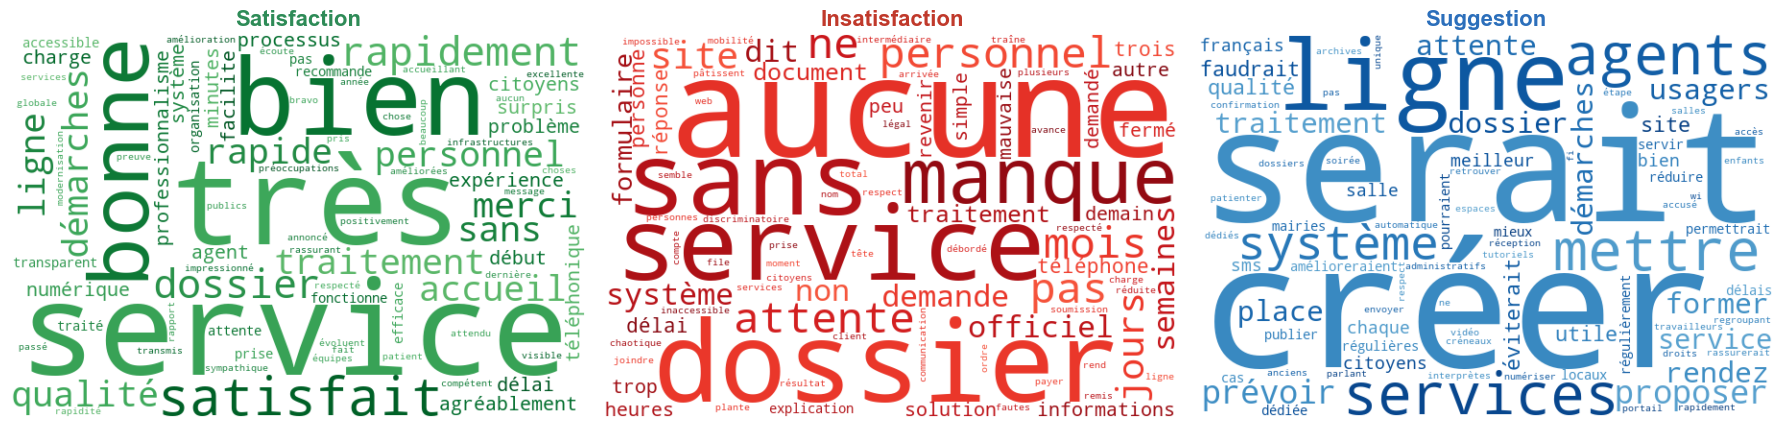

In [11]:
frequences_par_categorie = {
    categorie: Counter(jeton for jetons in df.loc[df["categorie"] == categorie, "jetons"] for jeton in jetons)
    for categorie in CATEGORIES
}

def fabrique_couleurs(nom_cmap):
    palette = plt.get_cmap(nom_cmap)
    generateur = random.Random(SEED)
    def choisir_couleur(*args, **kwargs):
        rouge, vert, bleu, _ = palette(generateur.uniform(0.55, 0.95))
        return f"rgb({int(rouge * 255)},{int(vert * 255)},{int(bleu * 255)})"
    return choisir_couleur


fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, categorie in zip(axes, CATEGORIES):
    nuage = WordCloud(width=600, height=400, background_color="white",
                      color_func=fabrique_couleurs(CMAPS_NUAGES[categorie]), max_words=80, random_state=SEED
                      ).generate_from_frequencies(frequences_par_categorie[categorie])
    ax.imshow(nuage, interpolation="bilinear")
    ax.set_title(categorie, fontsize=16, fontweight="bold", color=COULEURS[categorie])
    ax.axis("off")
plt.tight_layout()
plt.show()

## Les 15 termes les plus fréquents par catégorie

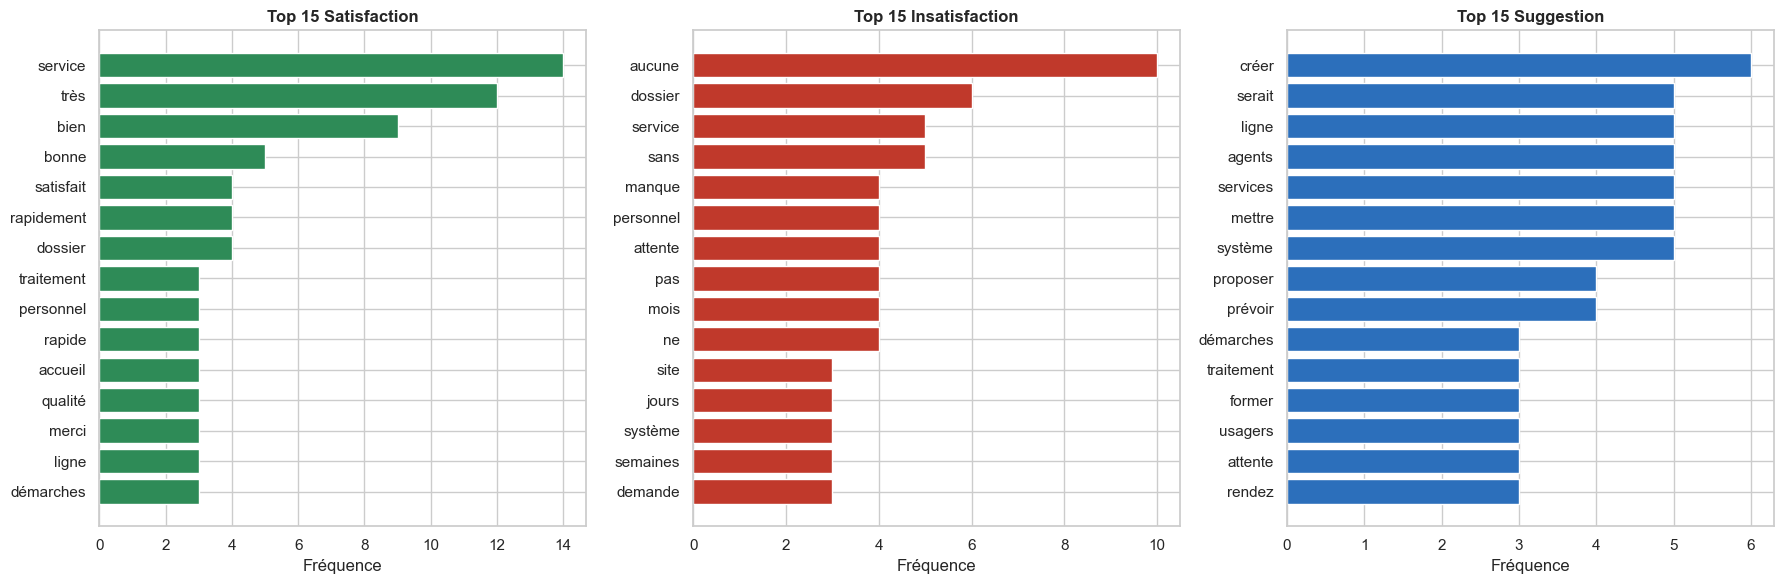

,Satisfaction,Insatisfaction,Suggestion
1,service (14),aucune (10),créer (6)
2,très (12),dossier (6),serait (5)
3,bien (9),service (5),ligne (5)
4,bonne (5),sans (5),agents (5)
5,satisfait (4),manque (4),services (5)
6,rapidement (4),personnel (4),mettre (5)
7,dossier (4),attente (4),système (5)
8,traitement (3),pas (4),proposer (4)
9,personnel (3),mois (4),prévoir (4)
10,rapide (3),ne (4),démarches (3)


In [12]:
NB_TERMES = 15
top_termes = {cat: frequences_par_categorie[cat].most_common(NB_TERMES) for cat in CATEGORIES}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, categorie in zip(axes, CATEGORIES):
    termes, effectifs = zip(*top_termes[categorie])
    ax.barh(termes[::-1], effectifs[::-1], color=COULEURS[categorie])
    ax.set_title(f"Top {NB_TERMES} {categorie}", fontweight="bold")
    ax.set_xlabel("Fréquence")
plt.tight_layout()
plt.show()

# Même information sous forme de tableau
tableau_top = pd.DataFrame({cat: [f"{terme} ({n})" for terme, n in top_termes[cat]] for cat in CATEGORIES})
tableau_top.index = range(1, NB_TERMES + 1)
display(tableau_top)

**Ce que je lis dans les nuages de mots et les fréquences** :

  -  Satisfaction : un vocabulaire de valence positive (très, bien, bonne, satisfait, rapide(ment), merci, qualité, accueil). Je remarque que merci apparaît 3 fois, en partie grâce à la traduction de akpe : la normalisation éwé a bien joué son rôle.
   - Insatisfaction : la classe est dominée par les négations et les manques : aucune (10 occurrences, c'est le terme le plus fréquent de la classe !), sans, pas, ne, manque, plus des durées d'attente (mois, jours, semaines, attente). Ça valide mon choix de conserver les négations : les avoir supprimées aurait effacé le signal principal de cette classe.
  -  Suggestion : des verbes d'action à l'infinitif (créer, mettre, proposer, prévoir, former) et le conditionnel serait, qu'on croise presque jamais dans les deux autres classes.
   - Les mots partagés : service, dossier, personnel, traitement, système, attente, démarches apparaissent dans plusieurs classes. C'est logique, tout le monde parle du même sujet : le service public. Ce qui sépare les classes, ce sont les mots de valence et les formes verbales, pas le thème. Je sais déjà que le plus dur sera de distinguer Satisfaction et Insatisfaction, qui parlent exactement des mêmes sujets.

# Partie 2: Modélisation
##  Vectorisation
### Choix de la méthode de vectorisation 

Mon choix : TF-IDF sur n-grammes de caractères (analyseur char_wb, de 2 à 5 caractères), avec sublinear_tf=True et strip_accents="unicode".

Voici mon raisonnement :

    Le corpus est minuscule (150 textes d'environ 9 mots) : c'est beaucoup trop petit pour entraîner des embeddings, et je n'ai pas de modèle pré-entraîné adapté à l'éwé/mina à disposition ;
    TF-IDF plutôt qu'un simple comptage : ça baisse le poids des mots présents partout (service, personnel) et ça met en avant les termes discriminants ;
    Des n-grammes de caractères plutôt que des mots : avec si peu de textes, beaucoup de mots n'apparaissent qu'une seule fois. Les sous-chaînes partagent l'information entre les variantes morphologiques (rapide, rapidement, rapidité ; satisfait, satisfaction) et entre les conjugaisons du conditionnel (serait, aiderait, faciliterait), qui sont justement le signal de la classe Suggestion ;
    Robustesse multilingue : les mots éwé/mina, absents de tout lexique français, sont quand même découpés en sous-chaînes exploitables ;
    strip_accents="unicode" : ça neutralise les variantes avec/sans accents, fréquentes dans des retours citoyens tapés rapidement sur mobile ;
    Pas de fuite de données : le vectoriseur est placé dans un Pipeline, donc il est ajusté uniquement sur les données d'entraînement.

Je vérifie aussi ce choix plus bas, sur le jeu d'entraînement uniquement : je le compare aux variantes à base de mots.
Découpage du dataset : 80 % entraînement / 20 % test (random_state fixé)


In [13]:
X = df["texte_nettoye"]
y = df["categorie"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

print(f"Entraînement : {len(X_train)} commentaires ({len(X_train) / len(df):.0%})")
print(f"Test         : {len(X_test)} commentaires ({len(X_test) / len(df):.0%})")
print("\nRépartition des classes :")
display(pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()}).loc[CATEGORIES])

Entraînement : 120 commentaires (80%)
Test         : 30 commentaires (20%)

Répartition des classes :


,train,test
categorie,,
Satisfaction,40,10
Insatisfaction,40,10
Suggestion,40,10


### Vérification empirique du choix de vectorisation (validation croisée sur le jeu d'**entraînement** uniquement)
je compare quatre représentations avec la même régression logistique, par validation croisée stratifiée 5 plis × 3 répétitions

In [14]:
validation_croisee = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

vectoriseurs_candidats = {
    "CountVectorizer (unigrammes)": CountVectorizer(strip_accents="unicode"),
    "TF-IDF (unigrammes)": TfidfVectorizer(strip_accents="unicode", sublinear_tf=True),
    "TF-IDF (unigrammes + bigrammes)": TfidfVectorizer(strip_accents="unicode", sublinear_tf=True, ngram_range=(1, 2)),
    "TF-IDF (n-grammes de caractères 2-5)": TfidfVectorizer(strip_accents="unicode", sublinear_tf=True,
                                                            analyzer="char_wb", ngram_range=(2, 5)),
}

lignes = []
for nom, vectoriseur in vectoriseurs_candidats.items():
    pipeline_test = Pipeline([("vec", vectoriseur),
                              ("clf", LogisticRegression(max_iter=1000, C=10, random_state=SEED))])
    scores = cross_val_score(pipeline_test, X_train, y_train, cv=validation_croisee, scoring="f1_macro")
    lignes.append({"Vectorisation": nom, "F1 macro (moyenne CV)": scores.mean(), "Écart-type": scores.std()})

comparaison_vectoriseurs = pd.DataFrame(lignes).sort_values("F1 macro (moyenne CV)", ascending=False).round(4)
display(comparaison_vectoriseurs.reset_index(drop=True))

,Vectorisation,F1 macro (moyenne CV),Écart-type
0,TF-IDF (n-grammes de caractères 2-5),0.6581,0.0688
1,CountVectorizer (unigrammes),0.6466,0.0918
2,TF-IDF (unigrammes),0.6338,0.0955
3,TF-IDF (unigrammes + bigrammes),0.6294,0.0971


Lecture des résultats. Les n-grammes de caractères sortent en tête avec le meilleur F1 macro moyen (~~ 0,658) et le plus petit écart-type, devant les approches à base de mots (≈ 0,63-0,65). Mais soyons honnêtes : les écarts entre les quatre options (<= 0,03) sont plus petits que les écart-types (≈ 0,07-0,10). Sur 120 textes, je ne peux pas affirmer qu'une représentation est significativement meilleure qu'une autre. Je garde quand même les n-grammes de caractères, pour trois raisons : (i) ils sont au moins aussi bons que les autres, (ii) le choix tient debout linguistiquement (morphologie du français, conditionnel, mots éwé/mina inconnus), et (iii) c'est la version la plus stable. Les représentations à base de mots restent utiles : je les réutilise plus bas pour interpréter le modèle, parce que les coefficients des n-grammes de caractères sont illisibles (ois, rait...)

### Vérification empirique de la stratégie éwé/mina (prétraitement)
Même protocole (validation croisée sur le jeu d'entraînement uniquement), cette fois pour comparer les trois stratégies vues plus haut

In [15]:
def creer_vectoriseur():
    # Vectoriseur retenu : TF-IDF sur n-grammes de caractères (2 à 5), limités aux frontières de mots.
    return TfidfVectorizer(strip_accents="unicode", sublinear_tf=True, analyzer="char_wb", ngram_range=(2, 5))


lignes = []
for strategie in ["conserver", "supprimer", "normaliser"]:
    textes_strategie = df["texte"].apply(pretraiter_texte, strategie_ewe=strategie).loc[X_train.index]
    pipeline_test = Pipeline([("vec", creer_vectoriseur()),
                              ("clf", LogisticRegression(max_iter=1000, C=10, random_state=SEED))])
    scores = cross_val_score(pipeline_test, textes_strategie, y_train, cv=validation_croisee, scoring="f1_macro")
    lignes.append({"Stratégie éwé/mina": strategie, "F1 macro (moyenne CV)": scores.mean(), "Écart-type": scores.std()})

display(pd.DataFrame(lignes).round(4))

,Stratégie éwé/mina,F1 macro (moyenne CV),Écart-type
0,conserver,0.6581,0.0688
1,supprimer,0.6551,0.0696
2,normaliser,0.6581,0.0688


Les trois stratégies donnent pratiquement le même résultat : F1 macro entre 0,655 et 0,658, avec des écarts d'environ 0,003, soit moins d'un seul exemple. En y réfléchissant, c'est normal : seuls 3 commentaires sur 150 sont mixtes, et un seul tombe dans le train (les deux autres finissent dans le test). L'effet est trop faible pour être mesuré par validation croisée. Je garde quand même la stratégie " normaliser ", par principe : elle rapproche akpe et nyuie du vocabulaire français équivalent et supprime les mots grammaticaux éwé. Mais je ne prétends pas qu'elle est démontrée meilleure : les données ne permettent tout simplement pas de le dire

## 2.2 Entraînement
J'entraîne quatre algorithmes différents, chacun dans son Pipeline TF-IDF - classifieur 

<table style="border-collaps: collaps; width:50%; " border="1">
   <tr> <th style ="text-align: center;">Algorithme </th>
    <th style ="text-align: center;">Pourquoi </th>
   </tr>
    <tr>
        <td>Logistic Regression</td>
        <td>Référence linéaire, coefficients interprétables</td>
    </tr>
    <tr>
        <td>SVM linéaire (LinearSVC)</td>
        <td>Très performant sur textes TF-IDF en haute dimension</td>
    </tr>
    <tr>
        <td>Naive Bayes multinomial</td>
        <td>Classique pour le texte, adapté aux petits corpus</td>
    </tr>
    <tr>
        <td>Random Forest</td>
        <td>Modèle non linéaire à base d'arbres, pour comparaison</td>
    </tr>
</table>

In [25]:
classifieurs = {
    "Logistic Regression": LogisticRegression(max_iter=1000, C=10, random_state=SEED),
    "SVM linéaire (LinearSVC)": LinearSVC(C=1.0, random_state=SEED),
    "Naive Bayes multinomial": MultinomialNB(alpha=0.5),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED),
}

pipelines = {nom: Pipeline([("tfidf", creer_vectoriseur()), ("clf", classifieur)])
             for nom, classifieur in classifieurs.items()}

for nom, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    print(f" {nom} entraîné sur {len(X_train)} commentaires")

taille_vocabulaire = len(pipelines["Logistic Regression"].named_steps["tfidf"].vocabulary_)
print(f"\nTaille du vocabulaire TF-IDF (n-grammes de caractères, train) : {taille_vocabulaire}")

 Logistic Regression entraîné sur 120 commentaires
 SVM linéaire (LinearSVC) entraîné sur 120 commentaires
 Naive Bayes multinomial entraîné sur 120 commentaires
 Random Forest entraîné sur 120 commentaires

Taille du vocabulaire TF-IDF (n-grammes de caractères, train) : 4731


## 2.3 Évaluation
### Accuracy et F1-score macro sur le jeu de test (20 %)

In [17]:
predictions_test = {nom: pipeline.predict(X_test) for nom, pipeline in pipelines.items()}

resultats = []
for nom, y_pred in predictions_test.items():
    resultats.append({
        "Modèle": nom,
        "Accuracy (test)": accuracy_score(y_test, y_pred),
        "F1 macro (test)": f1_score(y_test, y_pred, average="macro"),
        "Erreurs (sur %d)" % len(y_test): int((y_pred != y_test).sum()),
    })
tableau_synthese = pd.DataFrame(resultats)

### Matrice de confusion

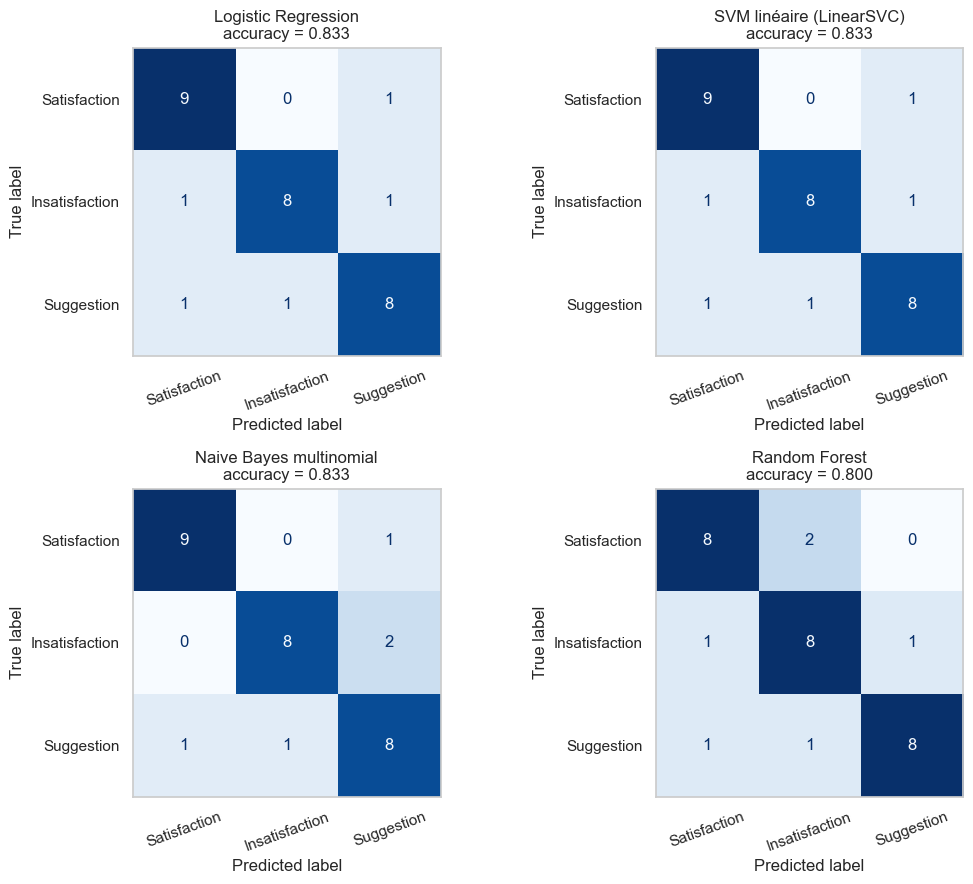

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (nom, y_pred) in zip(axes.ravel(), predictions_test.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=CATEGORIES, cmap="Blues",
                                            colorbar=False, ax=ax)
    ax.set_title(f"{nom}\naccuracy = {accuracy_score(y_test, y_pred):.3f}")
    ax.grid(False)
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

### Tableau de synthèse comparatif
Le jeu de test ne contient que 30 commentaires : un seul exemple fait bouger l'accuracy de 3,3 points. Pour juger la robustesse, j'ajoute donc le F1 macro en validation croisée (5 plis × 3 répétitions) sur l'ensemble des 150 commentaires. Le tableau est trié sur cette colonne, et le meilleur modèle pour la suite (analyse d'erreurs, démonstration) est choisi sur ce critère plutôt que sur 30 exemples.

In [19]:
cv_moyennes = {}
cv_ecarts = {}
for nom, pipeline in pipelines.items():
    scores = cross_val_score(clone(pipeline), X, y, cv=validation_croisee, scoring="f1_macro")
    cv_moyennes[nom], cv_ecarts[nom] = scores.mean(), scores.std()

tableau_synthese["F1 macro CV (moy.)"] = tableau_synthese["Modèle"].map(cv_moyennes)
tableau_synthese["F1 macro CV (écart-type)"] = tableau_synthese["Modèle"].map(cv_ecarts)
tableau_synthese = (tableau_synthese.sort_values("F1 macro CV (moy.)", ascending=False)
                                    .round(4).reset_index(drop=True))
display(tableau_synthese)

# Le meilleur modèle est choisi sur la validation croisée (150 textes).
meilleur_modele = tableau_synthese.loc[0, "Modèle"]
print("Meilleur modèle (F1 macro en validation croisée) :", meilleur_modele)
print("\nRapport de classification détaillé du meilleur modèle :")
print(classification_report(y_test, predictions_test[meilleur_modele], labels=CATEGORIES, digits=3))

,Modèle,Accuracy (test),F1 macro (test),Erreurs (sur 30),F1 macro CV (moy.),F1 macro CV (écart-type)
0,Logistic Regression,0.8333,0.8331,5,0.7236,0.0999
1,SVM linéaire (LinearSVC),0.8333,0.8331,5,0.7230,0.1071
2,Random Forest,0.8000,0.8013,6,0.6712,0.0982
3,Naive Bayes multinomial,0.8333,0.8347,5,0.6683,0.0902


Meilleur modèle (F1 macro en validation croisée) : Logistic Regression

Rapport de classification détaillé du meilleur modèle :
                precision    recall  f1-score   support

  Satisfaction      0.818     0.900     0.857        10
Insatisfaction      0.889     0.800     0.842        10
    Suggestion      0.800     0.800     0.800        10

      accuracy                          0.833        30
     macro avg      0.836     0.833     0.833        30
  weighted avg      0.836     0.833     0.833        30



**Lecture du tableau de synthèse**

  -  Sur le jeu de test (30 commentaires), trois modèles font 0,833 d'accuracy (5 erreurs chacun) et le Random Forest 0,800 (6 erreurs). Un exemple pèse 3,3 points, donc ces écarts (<=1 exemple) ne sont pas significatifs. Le fait que le Naive Bayes ait un F1 de 0,835 contre 0,833 pour les deux modèles linéaires (écart de 0,002) ne veut rien dire non plus.
  -  En validation croisée sur les 150 textes, la régression logistique (F1 macro 0,724) et le SVM linéaire (0,723) sont devant le Random Forest (0,671) et le Naive Bayes (0,668). L'écart-type (~~ 0,10) reste du même ordre que les différences, donc ce que je retiens surtout, c'est que les deux modèles linéaires sont au moins aussi bons que les autres et plus stables. C'est un résultat classique sur du texte TF-IDF avec peu de données.
  -  Le score de test (~~ 0,83) est plus haut que la validation croisée (~~ 0,72) : le découpage de test m'a été plutôt favorable, ou alors il est trop petit pour être fiable. Pour estimer la performance réelle attendue, je me fie donc à la validation croisée (~~ 0,70 ± 0,10).
   - Je choisis la régression logistique comme modèle final : meilleure validation croisée, et ses coefficients sont en plus interprétables.

**Lecture des matrices de confusion**. Sur le test, la régression logistique classe correctement 9, 8 et 8 exemples (sur 10 par classe) ; ses 5 erreurs sont dispersées un peu partout, sans confusion systématique visible à cette taille. Vu le peu d'observations par case, je m'appuie surtout sur la matrice hors-échantillon sur les 150 textes de la section suivante : la classe Suggestion est la mieux reconnue (41 / 50), et la confusion la plus fréquente est entre Satisfaction et Insatisfaction (23 des 44 erreurs). Ça rejoint ce que je voyais en partie 1 : les suggestions ont une forme très reconnaissable, alors qu'un avis positif et un avis négatif parlent des mêmes sujets.

### Analyse d'erreurs : exemples mal classés et hypothèses
Avec 30 exemples de test, les erreurs sont peu nombreuses et je ne peux pas en tirer grand-chose. Pour avoir assez de cas à analyser, je regroupe :

- les erreurs sur le jeu de test (tous modèles confondus) ;
-  les erreurs hors-échantillon de mon meilleur modèle sur les 150 commentaires (prédictions obtenues par validation croisée : chaque commentaire est prédit par un modèle qui ne l'a jamais vu). C'est ce qui se rapproche le plus d'une évaluation sur des données neuves.

In [20]:
# 1) Erreurs sur le jeu de test, tous modèles confondus
erreurs_test = []
for nom, y_pred in predictions_test.items():
    for indice, vrai, predit in zip(y_test.index, y_test, y_pred):
        if vrai != predit:
            erreurs_test.append({"id": df.loc[indice, "id"], "texte": df.loc[indice, "texte"],
                                 "vraie classe": vrai, "classe prédite": predit, "modèle": nom})
erreurs_test = pd.DataFrame(erreurs_test)
print("Erreurs sur le jeu de test (tous modèles) :")
if erreurs_test.empty:
    print("Aucune erreur.")
else:
    display(erreurs_test.groupby(["id", "texte", "vraie classe", "classe prédite"])["modèle"]
                        .apply(", ".join).reset_index())

# 2) Erreurs hors-échantillon du meilleur modèle (validation croisée 5 plis sur 150 textes)
predictions_oof = cross_val_predict(clone(pipelines[meilleur_modele]), X, y,
                                    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED))
print("Matrice de confusion hors-échantillon (lignes = vraie classe, colonnes = classe prédite) :")
display(pd.crosstab(y.rename("vraie classe"), pd.Series(predictions_oof, index=y.index, name="classe prédite"))
          .loc[CATEGORIES, CATEGORIES])

masque_erreurs = predictions_oof != y.values
erreurs_oof = pd.DataFrame({
    "id": df.loc[masque_erreurs, "id"], "texte": df.loc[masque_erreurs, "texte"],
    "texte nettoyé": X[masque_erreurs], "vraie classe": y[masque_erreurs],
    "classe prédite": predictions_oof[masque_erreurs],
})
print(f"\nErreurs hors-échantillon de « {meilleur_modele} » : {len(erreurs_oof)} / {len(df)} "
      f"(accuracy CV = {1 - len(erreurs_oof) / len(df):.3f})")
display(erreurs_oof.reset_index(drop=True))

Erreurs sur le jeu de test (tous modèles) :


,id,texte,vraie classe,classe prédite,modèle
0,14,Numériser les archives pour retrouver rapidement les anciens dossiers.,Suggestion,Satisfaction,"Logistic Regression, SVM linéaire (LinearSVC), Naive Bayes multinomial, Random Forest"
1,20,L'agent était patient et à l'écoute de mes préoccupations.,Satisfaction,Insatisfaction,Random Forest
2,20,L'agent était patient et à l'écoute de mes préoccupations.,Satisfaction,Suggestion,"Logistic Regression, SVM linéaire (LinearSVC), Naive Bayes multinomial"
3,23,"Système de file d'attente chaotique, pas de respect de l'ordre d'arrivée.",Insatisfaction,Satisfaction,"Logistic Regression, SVM linéaire (LinearSVC), Random Forest"
4,23,"Système de file d'attente chaotique, pas de respect de l'ordre d'arrivée.",Insatisfaction,Suggestion,Naive Bayes multinomial
5,90,Ouvrir un guichet spécial pour les personnes âgées et handicapées.,Suggestion,Insatisfaction,"Logistic Regression, SVM linéaire (LinearSVC), Naive Bayes multinomial, Random Forest"
6,109,"Je suis venu à l'ouverture, on m'a dit de revenir à 14h.",Insatisfaction,Suggestion,"Logistic Regression, SVM linéaire (LinearSVC), Naive Bayes multinomial, Random Forest"
7,114,Service numérique fonctionnel et accessible depuis mon téléphone.,Satisfaction,Insatisfaction,Random Forest


Matrice de confusion hors-échantillon (lignes = vraie classe, colonnes = classe prédite) :


classe prédite,Satisfaction,Insatisfaction,Suggestion
vraie classe,,,
Satisfaction,34,12,4
Insatisfaction,11,31,8
Suggestion,3,6,41



Erreurs hors-échantillon de « Logistic Regression » : 44 / 150 (accuracy CV = 0.707)


,id,texte,texte nettoyé,vraie classe,classe prédite
0,3,Envoyer des SMS de confirmation lors de chaque étape du traitement.,envoyer sms confirmation chaque étape traitement,Suggestion,Insatisfaction
1,4,Prévoir des interprètes pour les citoyens ne parlant pas le français.,prévoir interprètes citoyens ne parlant pas français,Suggestion,Insatisfaction
2,5,Le formulaire en ligne plante au moment de la soumission.,formulaire ligne plante moment soumission,Insatisfaction,Suggestion
3,6,Le personnel semble débordé et les citoyens en pâtissent.,personnel semble débordé citoyens pâtissent,Insatisfaction,Satisfaction
4,10,Le personnel fait preuve de beaucoup de professionnalisme.,personnel fait preuve beaucoup professionnalisme,Satisfaction,Insatisfaction
5,12,Traitement discriminatoire selon la tête du client.,traitement discriminatoire tête client,Insatisfaction,Suggestion
6,14,Numériser les archives pour retrouver rapidement les anciens dossiers.,numériser archives retrouver rapidement anciens dossiers,Suggestion,Satisfaction
7,15,J'ai dû payer un intermédiaire pour que mon dossier avance.,payer intermédiaire dossier avance,Insatisfaction,Suggestion
8,18,"Le délai annoncé a été respecté, c'est rassurant.",délai annoncé respecté rassurant,Satisfaction,Insatisfaction
9,19,On m'a remis un document avec des fautes dans mon nom.,remis document fautes nom,Insatisfaction,Satisfaction


**Termes les plus influents par classe** Les n-grammes de caractères ne sont pas lisibles (ois, rait...). Donc, uniquement pour l'interprétation, j'entraîne sur le train une régression logistique sur des mots (unigrammes + bigrammes) : ses coefficients montrent quels mots poussent vers chaque classe, et donc pourquoi certaines erreurs se produisent

In [21]:
modele_interpretation = Pipeline([
    ("tfidf", TfidfVectorizer(strip_accents="unicode", sublinear_tf=True, ngram_range=(1, 2))),
    ("clf", LogisticRegression(max_iter=1000, C=10, random_state=SEED)),
]).fit(X_train, y_train)

noms_termes = np.array(modele_interpretation.named_steps["tfidf"].get_feature_names_out())
coefficients = modele_interpretation.named_steps["clf"].coef_
classes_interpretation = modele_interpretation.named_steps["clf"].classes_

influents = pd.DataFrame({
    classe: noms_termes[np.argsort(coefficients[i])[::-1][:10]] for i, classe in enumerate(classes_interpretation)
})
influents.index = range(1, 11)
display(influents[CATEGORIES])

,Satisfaction,Insatisfaction,Suggestion
1,tres,aucune,mettre
2,bien,mois,proposer
3,service,manque,prevoir
4,rapidement,jours,serait
5,bonne,trop,agents
6,satisfait,telephone,creer
7,rapide,mauvaise,former
8,surpris,autre,dediee
9,agreablement,semaines,eviterait
10,agreablement surpris,simple,amelioreraient


**Analyse de 5 exemples mal classés (régression logistique) et  mes hypothèses.**

  -  id 75 " Service de première classe, je n'ai aucune remarque négative." (Satisfaction -> Insatisfaction). C'est une double négation : aucune est le terme le plus fréquent de l'Insatisfaction (10 occurrences) et négative lui ressemble beaucoup. Un modèle « sac de mots » ne comprend pas que nier quelque chose de négatif, c'est positif : il applique un raccourci lexical.
  -  id 60 << Le personnel est impoli et peu professionnel. >> (Insatisfaction -> Satisfaction). Mon hypothèse : impoli n'apparaît qu'une seule fois dans tout le corpus (donc jamais vu à l'entraînement au moment où cet exemple est évalué), alors que professionnel évoque les commentaires positifs (<< professionnalisme >>,<< très professionnel >>). Et la négation peu ne se rattache pas au mot qui la suit dans une représentation sans ordre. Cause : mot rare + négation non gérée.
  -  id 87 << Augmenter le nombre de guichets ouverts aux heures de pointe. >> (Suggestion -> Insatisfaction), et même type d'erreur pour les ids 90 et 36 (<< Ouvrir un guichet... .>>, << Allonger les horaires... >>). Les verbes augmenter, ouvrir, allonger n'apparaissent chacun qu'une seule fois dans le corpus (donc inconnus du modèle quand ils sont évalués), contrairement aux verbes fréquents de suggestion (créer, mettre, proposer, prévoir). Le modèle se rabat alors sur les mots du thème (guichets, ouverts, horaires), qui sont partagés avec des plaintes (<< seulement 2 guichets ouverts sur 8 >>). Cause : verbe de suggestion inconnu + confusion entre thème et classe.
  -  id 14 << Numériser les archives pour retrouver rapidement les anciens dossiers. >> (Suggestion -> Satisfaction, erreur commune aux 4 modèles sur le test). rapidement apparaît 4 fois en Satisfaction contre 1 seule fois en Suggestion, et numériser n'apparaît qu'une fois dans tout le corpus. Cause : mot de valence positive dans une phrase qui est en fait une proposition, et vocabulaire d'entraînement trop petit.
   - id 104 << Les horaires affichés ne correspondent pas à la réalité. >> (Insatisfaction -> Suggestion). Les n-grammes de caractères de affichés sont très proches de afficher (<< Afficher clairement les délais... >>, classe Suggestion) : le modèle à n-grammes rapproche des formes morphologiquement proches qui appartiennent à des classes différentes (affichage apparaît aussi dans une plainte). La négation ne ... pas n'a pas pesé assez lourd.

**Les causes générales (qu'on retrouve aussi sur les autres erreurs)**:

    la négation et sa portée ne sont pas gérées par un sac de mots, même avec des bigrammes (ids 75, 60, 98 << sans paperasse inutile >>, 71 << sans complications >>) ;
    les chiffres supprimés par le prétraitement (imposé par le sujet) : << Je n'ai attendu que 10 minutes >> (id 47, Satisfaction -> Insatisfaction) devient attendu minutes pris charge, qui ressemble à une plainte ; pareil pour « revenir à 14h » (id 109, test) ;
    le vocabulaire d'entraînement minuscule : des mots rares ou jamais vus (impoli, fardeau, chaotique...) ;
    l'ambiguïté des étiquettes : << Publier les résultats des enquêtes de satisfaction pour plus de transparence >> (id 26, prédite Satisfaction) pourrait raisonnablement appartenir à deux classes ;
    les mots-thème partagés (dossier, personnel, délai), sans valeur discriminante.

# Partie 3: Qualité du code & restitution
## 3-1 Mini-démonstration sur de nouveaux textes 
Une fonction `predire_categorie` applique le même prétraitement et le meilleur modèle à un nouveau commentaire, y compris un commentaire mixte français/éwé.
- Cette démonstration est aussi disponible sous forme d'**interface web Streamlit** (`app.py`, modèle sauvegardé dans `modele_classification.joblib` par `entrainer_modele.py`) voir le README.

In [22]:
def predire_categorie(commentaire, modele=None):
    # Prédit la catégorie d'un nouveau commentaire brut (même prétraitement que l'entraînement).
    modele = modele or pipelines[meilleur_modele]
    return modele.predict([pretraiter_texte(commentaire)])[0]


nouveaux_commentaires = [
    "L'agent m'a reçu avec le sourire et mon dossier a été traité en une journée.",
    "Personne ne répond au téléphone et on me fait revenir sans cesse.",
    "Il faudrait ajouter plus de guichets le samedi matin.",
    "Akpe na wò, service nyuie !",
]
for commentaire in nouveaux_commentaires:
    print(f"{predire_categorie(commentaire):<15} <- {commentaire}")

Insatisfaction  <- L'agent m'a reçu avec le sourire et mon dossier a été traité en une journée.
Insatisfaction  <- Personne ne répond au téléphone et on me fait revenir sans cesse.
Suggestion      <- Il faudrait ajouter plus de guichets le samedi matin.
Satisfaction    <- Akpe na wò, service nyuie !


### 3-2 Sauvegarde du modèle pour l'application
Je sauvegarde la régression logistique (mon meilleur modèle) et je la réentraîne sur les 150 commentaires : pour l'application, autant mettre à profit toutes les données disponibles. Les métriques affichées dans la barre latérale de l'app (F1 macro CV ≈ 0,724 +_ 0,1) sont écrites dans metriques_modele.json.

In [23]:
import json
import joblib

#Choix du modèle à sauvegarder 

NOM_MODELE_A_SAUVEGARDER = "Logistic Regression"
ENTRAINER_SUR_TOUT_LE_JEU = True   

modele_a_sauvegarder = clone(pipelines[NOM_MODELE_A_SAUVEGARDER])
if ENTRAINER_SUR_TOUT_LE_JEU:
    modele_a_sauvegarder.fit(X, y)
    nb_textes_entrainement = len(X)
else:
    modele_a_sauvegarder.fit(X_train, y_train)
    nb_textes_entrainement = len(X_train)

joblib.dump(modele_a_sauvegarder, "modele_classification.joblib")

#  Métriques lues par l'application (sidebar)
metriques = {
    "f1_macro_cv_moyenne": round(float(cv_moyennes[NOM_MODELE_A_SAUVEGARDER]), 3),
    "f1_macro_cv_ecart_type": round(float(cv_ecarts[NOM_MODELE_A_SAUVEGARDER]), 3),
    "nb_commentaires_entrainement": int(nb_textes_entrainement),
    "classes": list(modele_a_sauvegarder.classes_),
}
with open("metriques_modele.json", "w", encoding="utf-8") as fichier:
    json.dump(metriques, fichier, ensure_ascii=False, indent=2)

print("Fichiers créés : modele_classification.joblib, metriques_modele.json")
print(metriques)

Fichiers créés : modele_classification.joblib, metriques_modele.json
{'f1_macro_cv_moyenne': 0.724, 'f1_macro_cv_ecart_type': 0.1, 'nb_commentaires_entrainement': 150, 'classes': ['Insatisfaction', 'Satisfaction', 'Suggestion']}


## 3-3 Conclusion, limites et pistes d'améliorationabs
### Bilan
Le pipeline complet est en place : exploration, nettoyage (accents, ponctuation, chiffres, éwé/mina, stopwords justifiés), TF-IDF sur n-grammes de caractères, 4 classifieurs, évaluation sur test et en validation croisée, analyse d'erreurs.

    Performance : environ 0,83 d'accuracy / F1 macro sur le jeu de test (30 exemples), et autour de 0,72 de F1 macro en validation croisée pour la régression logistique et le SVM linéaire. Les valeurs de validation croisée sont, je pense, les plus réalistes.
    Forces : classes équilibrées, Suggestion bien reconnue (sa forme est très régulière), prétraitement sans fuite de données, et tout est reproductible (SEED = 42).
    Faiblesse principale : la confusion Satisfaction - Insatisfaction (23 des 44 erreurs hors-échantillon), à cause des négations, du vocabulaire rare et des thèmes partagés.

**Limites de l'approche**

    Très peu de données : 150 textes, 30 en test. Un exemple vaut 3,3 points et l'écart-type de la validation croisée est ≈ 0,10, donc les différences entre modèles sont à peine interprétables.
    Représentation sans ordre ni contexte : le TF-IDF ne comprend ni la négation, ni la portée des adverbes, ni l'ironie (exemples ids 75 et 60).
    Suppression des chiffres (imposée par le sujet) : on perd des informations utiles (10 minutes  vs  3 heures ).
    Éwé/mina : seulement 3 commentaires mixtes, un lexique de 8 mots construit à la main et des gloses non validées par un locuteur natif ; l'effet n'est d'ailleurs pas mesurable ici.
    Jeu de données très homogène (phrases courtes, formulations proches, classes parfaitement équilibrées) : sur de vrais retours citoyens (plus longs, bruités, plus mélangés à l'éwé/mina, classes déséquilibrées), les performances seraient probablement plus basses.
    Hyperparamètres non optimisés et un seul découpage train/test.

**Pistes d'amélioration**

    Fine-tuner un modèle pré-entraîné multilingue (CamemBERT, XLM-R, ou un modèle couvrant les langues africaines comme AfroXLMR) : il comprend le contexte et la négation, et gérerait mieux les phrases mixtes français/éwé-mina.
    Gérer explicitement la négation et les nombres : marquer la portée des négations (pas_respecté), remplacer les nombres par un jeton NUM (ou des catégories  court/long ) au lieu de les supprimer.
    Collecter plus de données et faire de l'augmentation : plus de commentaires, surtout mixtes éwé/mina ; augmentation par paraphrase ou rétro-traduction ; lexique éwé/mina validé par des locuteurs et détection de langue.
    Être plus rigoureux sur l'évaluation : optimisation des hyperparamètres par validation croisée imbriquée, intervalles de confiance sur les scores, ensemble LR + SVM.

La démonstration ci-dessus illustre d'ailleurs ces limites :  L'agent m'a reçu avec le sourire...  est classé Insatisfaction, tout simplement parce que ce vocabulaire n'existe pas dans le jeu d'entraînement..

## 3-4 Reproductibilité
- **Graine fixée** : `SEED = 42` (NumPy, `random`, `train_test_split`, validations croisées, modèles, nuages de mots).
- **Installation** : `pip install -r requirements.txt` , puis `jupyter notebook`.
- **Pas de fuite de données** : tout ce qui est " appris " (TF-IDF, classifieurs) est ajusté sur le jeu d'entraînement via des `Pipeline`.

In [24]:
import sys, sklearn, matplotlib, wordcloud
print("Python      :", sys.version.split()[0])
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib  :", matplotlib.__version__)
print("seaborn     :", sns.__version__)
print("wordcloud   :", wordcloud.__version__)

Python      : 3.14.4
pandas      : 2.3.3
numpy       : 2.4.4
scikit-learn: 1.8.0
matplotlib  : 3.10.8
seaborn     : 0.13.2
wordcloud   : 1.9.6
